# JS14 — Tugas Tambahan: CNN untuk Dataset Teks URL

Notebook ini memperluas [praktikum CNN gambar](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js14-convolutional-neural-network/praktikum-1) ke data teks yang disediakan: `dataset/dataset_B_05_2020 (1).csv`. Tugas teks ini merupakan eksperimen tambahan, bukan langkah asli Cat vs Dog.

**Tujuan:** menguji apakah CNN dapat mengklasifikasi teks URL menjadi legitimate atau phishing. Gunakan **CNN 1D berbasis karakter**: URL → ID karakter → Embedding → Conv1D → GlobalMaxPooling1D → Dense → sigmoid. URL diperlakukan sebagai teks; 87 kolom fitur numerik lain tidak digunakan. Tidak ada URL yang dikunjungi dan tidak ada dataset tambahan yang diunduh.

Ikuti langkah secara berurutan dengan kernel **Python 3 (.venv)**. Perbandingan dengan CNN gambar bersifat konseptual; angka akurasi dari dua dataset dengan tugas berbeda tidak dapat digunakan untuk menyatakan bahwa satu jenis CNN lebih baik.

## Langkah 1 — Import library dan tentukan lokasi dataset
TensorFlow digunakan untuk TextVectorization, Embedding, dan CNN 1D. Scikit-learn digunakan untuk pembagian data, metrik, serta pembanding TF-IDF + Logistic Regression.

In [1]:
import os
from pathlib import Path
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '4')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '2')
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import tensorflow as tf
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay)
SEED = 42
tf.keras.utils.set_random_seed(SEED)
HERE = Path.cwd().resolve()
BASE = HERE if (HERE / 'dataset').is_dir() else HERE / 'Pertemuan 14'
assert (BASE / 'dataset').is_dir(), f'Dataset tidak ditemukan dari {HERE}'
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
print('Folder data:', BASE / 'dataset')
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from urllib.parse import urlsplit
CSV_PATH = BASE / 'dataset' / 'dataset_B_05_2020 (1).csv'
raw = pd.read_csv(CSV_PATH)
print('Ukuran CSV:', raw.shape)
display(raw[['url', 'status']].head())
display(raw['status'].value_counts().rename_axis('kelas').to_frame('jumlah'))

TensorFlow: 2.21.0


GPU: []
Folder data: E:\Kuliah\Website\Machine-Learning\Pertemuan 14\dataset


Ukuran CSV: (11430, 89)


,url,status
0,http://www.crestonwood.com/router.php,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,phishing
2,https://support-appleld.com.secureupdate.duila...,phishing
3,http://rgipt.ac.in,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,legitimate


,jumlah
kelas,
legitimate,5715
phishing,5715


## Langkah 2 — Pilih teks dan target, periksa kualitas data
Gunakan `url` sebagai input dan `status` sebagai target: legitimate=0, phishing=1. Buang nilai kosong dan duplikasi URL. Periksa konflik label sebelum deduplikasi agar label yang berbeda pada URL sama tidak diam-diam diabaikan. Huruf dan tanda baca URL dipertahankan karena memiliki makna struktural.

Duplikasi URL dibuang: 1
Jumlah data bersih: 11429


,jumlah
status,
legitimate,5715
phishing,5714


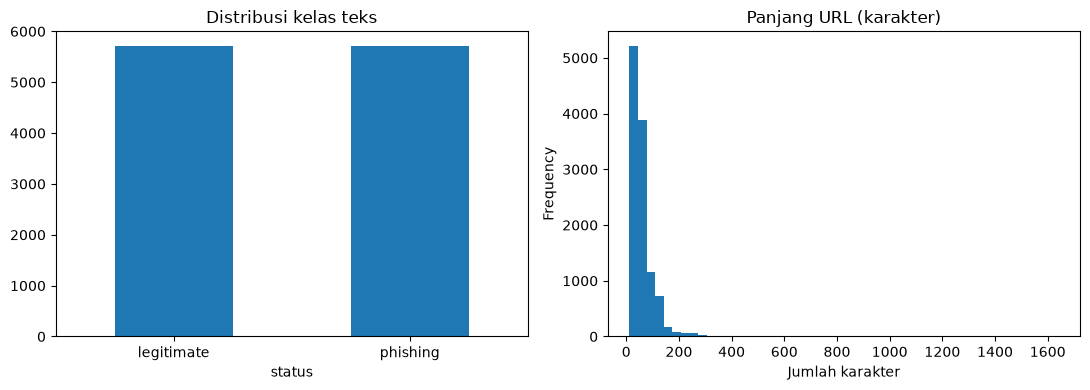

In [2]:
data = raw[['url', 'status']].dropna().copy()
data['url'] = data['url'].astype(str).str.strip()
data['status'] = data['status'].astype(str).str.strip().str.lower()
data = data[data['url'].str.len() > 0]
assert set(data['status']) == {'legitimate', 'phishing'}
conflicts = data.groupby('url')['status'].nunique()
assert not (conflicts > 1).any(), 'Ditemukan URL dengan label bertentangan'
duplicates = int(data['url'].duplicated().sum())
data = data.drop_duplicates('url').reset_index(drop=True)
data['label'] = data['status'].map({'legitimate': 0, 'phishing': 1}).astype('int32')
print('Duplikasi URL dibuang:', duplicates)
print('Jumlah data bersih:', len(data))
display(data.groupby('status')['url'].agg(jumlah='size'))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
data['status'].value_counts().plot.bar(ax=axes[0], rot=0, title='Distribusi kelas teks')
data['url'].str.len().plot.hist(bins=50, ax=axes[1], title='Panjang URL (karakter)')
axes[1].set_xlabel('Jumlah karakter')
plt.tight_layout()
plt.show()

## Langkah 3 — Pembagian latih, validasi, dan uji
Lakukan split stratified 70% latih, 15% validasi, 15% uji (pembulatan sesuai jumlah sampel). Data uji hanya dipakai setelah pelatihan. Tidak ada URL identik lintas split. Split dilakukan per URL, bukan per domain; domain yang sama dapat muncul pada lebih dari satu split, sehingga hasil tidak menjamin kemampuan pada domain baru.

In [3]:
train_df, remaining = train_test_split(data, test_size=0.30, random_state=SEED, stratify=data['label'])
val_df, test_df = train_test_split(remaining, test_size=0.5, random_state=SEED, stratify=remaining['label'])
assert not (set(train_df.url) & set(test_df.url))
assert not (set(train_df.url) & set(val_df.url))
assert not (set(val_df.url) & set(test_df.url))
display(pd.DataFrame([{'split': name, 'sampel': len(frame), 'phishing': int(frame.label.sum()),
                       'legitimate': int((frame.label==0).sum())}
                      for name, frame in [('latih', train_df), ('validasi', val_df), ('uji', test_df)]]))
def host(url):
    try:
        return (urlsplit(url if '://' in url else 'http://' + url).hostname or '').lower()
    except ValueError:
        return ''
train_hosts = {host(u) for u in train_df.url} - {''}
test_hosts = {host(u) for u in test_df.url} - {''}
print('Jumlah hostname yang muncul pada latih dan uji:', len(train_hosts & test_hosts))

,split,sampel,phishing,legitimate
0,latih,8000,4000,4000
1,validasi,1714,857,857
2,uji,1715,857,858


Jumlah hostname yang muncul pada latih dan uji: 349


## Langkah 4 — Ubah teks menjadi urutan karakter
`TextVectorization` diadaptasi **hanya pada data latih**. Gunakan maksimal 128 token (termasuk padding dan token tak dikenal), panjang urutan 256, tanpa standardisasi, serta pemisahan per karakter. Urutan pendek diberi padding 0; urutan panjang dipotong. Laporkan persentase URL yang terpotong agar batas representasi terlihat. Tidak memakai embedding pretrained.

In [4]:
MAX_TOKENS, SEQUENCE_LENGTH = 128, 256
vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS, standardize=None, split='character',
    output_mode='int', output_sequence_length=SEQUENCE_LENGTH)
train_text = tf.constant(train_df.url.tolist())
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(train_text).batch(256))
X_train = vectorizer(train_text).numpy()
X_val = vectorizer(tf.constant(val_df.url.tolist())).numpy()
X_test = vectorizer(tf.constant(test_df.url.tolist())).numpy()
y_train, y_val, y_test = [frame.label.to_numpy() for frame in (train_df, val_df, test_df)]
vocab_size = len(vectorizer.get_vocabulary())
print('Jumlah token:', vocab_size, '| Contoh kosakata:', vectorizer.get_vocabulary()[:25])
print('Bentuk tensor:', X_train.shape, X_val.shape, X_test.shape)
for name, frame in [('latih', train_df), ('validasi', val_df), ('uji', test_df)]:
    print(f'{name}: URL terpotong = {(frame.url.str.len() > SEQUENCE_LENGTH).mean():.2%}')
print('Contoh 30 ID karakter:', X_train[0, :30])

Jumlah token: 99 | Contoh kosakata: ['', '[UNK]', np.str_('t'), np.str_('/'), np.str_('e'), np.str_('o'), np.str_('a'), np.str_('p'), np.str_('s'), np.str_('.'), np.str_('c'), np.str_('i'), np.str_('r'), np.str_('h'), np.str_('n'), np.str_('m'), np.str_('w'), np.str_('l'), np.str_('d'), np.str_('u'), np.str_(':'), np.str_('-'), np.str_('b'), np.str_('g'), np.str_('f')]
Bentuk tensor: (8000, 256) (1714, 256) (1715, 256)
latih: URL terpotong = 1.16%
validasi: URL terpotong = 1.05%
uji: URL terpotong = 1.22%
Contoh 30 ID karakter: [13  2  2  7 20  3  3  6 10 59  6 17 15  6  9  6 42  0  0  0  0  0  0  0
  0  0  0  0  0  0]


## Langkah 5 — Bangun model CNN 1D
Embedding 32 dimensi memetakan ID karakter menjadi vektor yang dipelajari. Conv1D 64 filter dengan kernel 5 mendeteksi pola lokal sepanjang lima karakter. Global max pooling memilih respons fitur terkuat sepanjang urutan, lalu Dense 64 dan dropout 0,3 menghasilkan satu probabilitas phishing.

Padding memakai ID 0 dengan embedding yang dipelajari; Conv1D tidak meneruskan masking otomatis, sehingga panjang/pola padding dapat turut memengaruhi model. Ini merupakan model awal yang sederhana.

In [5]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
text_cnn = tf.keras.Sequential([
    tf.keras.Input(shape=(SEQUENCE_LENGTH,), dtype='int32'),
    tf.keras.layers.Embedding(input_dim=vocab_size, output_dim=32),
    tf.keras.layers.Conv1D(filters=64, kernel_size=5, activation='relu'),
    tf.keras.layers.GlobalMaxPooling1D(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')
], name='CNN_1D_URL_Text')
text_cnn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                 loss='binary_crossentropy', metrics=['accuracy'])
text_cnn.summary()

Model: "CNN_1D_URL_Text"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 256, 32)        │         3,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 252, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,697 (69.13 KB)

 Trainable params: 17,697 (69.13 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 6 — Latih model dan tampilkan kurva
Gunakan batch 64, maksimal 15 epoch, dan early stopping berdasarkan loss validasi dengan patience 3. Bobot terbaik berdasarkan validasi dipulihkan. Threshold klasifikasi ditetapkan 0,5 dan tidak disetel memakai data uji. Seluruh data latih bersih digunakan.

Epoch 1/15


125/125 - 59s - 470ms/step - accuracy: 0.7346 - loss: 0.5389 - val_accuracy: 0.8209 - val_loss: 0.3999


Epoch 2/15


125/125 - 11s - 86ms/step - accuracy: 0.8303 - loss: 0.3767 - val_accuracy: 0.8547 - val_loss: 0.3281


Epoch 3/15


125/125 - 7s - 52ms/step - accuracy: 0.8765 - loss: 0.3036 - val_accuracy: 0.8874 - val_loss: 0.2808


... (12 outputs left out)

Epoch 10/15


125/125 - 5s - 41ms/step - accuracy: 0.9703 - loss: 0.0943 - val_accuracy: 0.8991 - val_loss: 0.2656


Waktu latih: 123.25 detik; epoch terjalankan: 10
Epoch dengan loss validasi terendah: 7


,accuracy,loss,val_accuracy,val_loss
epoch mulai 0,,,,
0,0.734625,0.538916,0.820887,0.399886
1,0.830250,0.376684,0.854726,0.328146
2,0.876500,0.303592,0.887398,0.280811
3,0.899000,0.251709,0.900233,0.255934
4,0.917625,0.212113,0.906068,0.241429
5,0.933250,0.177432,0.903150,0.243717
6,0.945625,0.150113,0.908985,0.234207
7,0.956875,0.124661,0.906068,0.248371
8,0.964375,0.108293,0.910735,0.240106


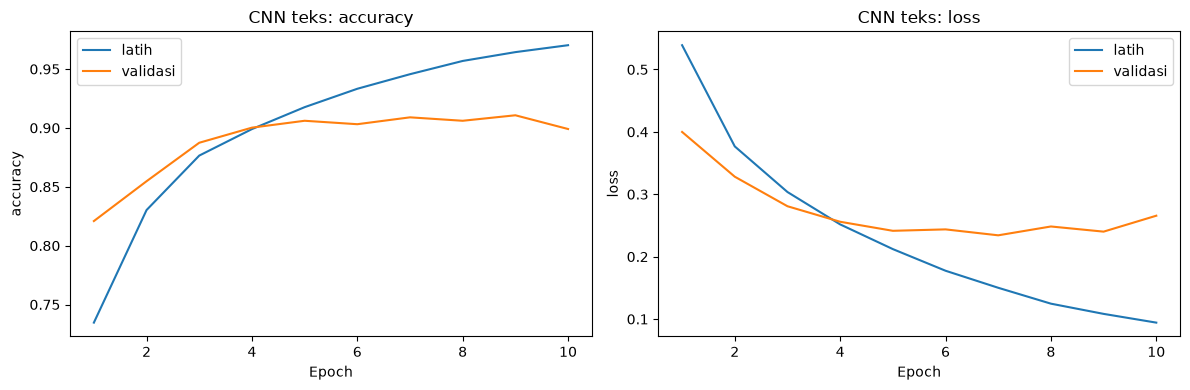

In [6]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
start = time.perf_counter()
history = text_cnn.fit(X_train, y_train, validation_data=(X_val, y_val),
                       epochs=15, batch_size=64, callbacks=[early_stop], verbose=2)
cnn_seconds = time.perf_counter() - start
print(f'Waktu latih: {cnn_seconds:.2f} detik; epoch terjalankan: {len(history.history["loss"])}')
print('Epoch dengan loss validasi terendah:', int(np.argmin(history.history['val_loss'])) + 1)
display(pd.DataFrame(history.history).rename_axis('epoch mulai 0'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['accuracy', 'loss']):
    ax.plot(range(1, len(history.history[metric])+1), history.history[metric], label='latih')
    ax.plot(range(1, len(history.history[metric])+1), history.history['val_'+metric], label='validasi')
    ax.set(xlabel='Epoch', ylabel=metric, title=f'CNN teks: {metric}')
    ax.legend()
plt.tight_layout()
plt.show()

## Langkah 7 — Pembanding TF-IDF karakter + Logistic Regression
Pembanding membantu menilai apakah model neural memberi manfaat pada dataset ini. Gunakan split yang sama, TF-IDF character n-gram 3–5, maksimal 30.000 fitur, dan Logistic Regression. Seluruh fitting TF-IDF dan classifier hanya menggunakan data latih. Waktu kedua metode mencakup `fit` masing-masing; CNN menggunakan embedding yang dipelajari saat fit, sementara vectorization awal terpisah, jadi ini bukan perbandingan benchmark waktu end-to-end.

In [7]:
baseline = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=30000,
                            min_df=2, lowercase=False)),
    ('classifier', LogisticRegression(max_iter=500, random_state=SEED))
])
start = time.perf_counter()
baseline.fit(train_df.url, y_train)
baseline_seconds = time.perf_counter() - start
print(f'Waktu fit pembanding: {baseline_seconds:.2f} detik')

Waktu fit pembanding: 5.46 detik


## Langkah 8 — Evaluasi pada data uji
Laporkan accuracy, precision, recall, F1, ROC-AUC, dan average precision dengan kelas positif phishing. Prediksi CNN memakai bobot dari epoch dengan loss validasi terendah, bukan bobot yang dipilih berdasarkan uji.

,model,accuracy,precision,recall,F1,ROC-AUC,average precision,waktu_fit_detik
0,CNN 1D karakter,0.910787,0.880130,0.950992,0.914190,0.972516,0.975835,123.250522
1,TF-IDF + Logistic Regression,0.918950,0.908884,0.931155,0.919885,0.978924,0.980931,5.464208


Loss uji CNN: 0.2259991616010666
              precision    recall  f1-score   support

  legitimate     0.9468    0.8706    0.9071       858
    phishing     0.8801    0.9510    0.9142       857

    accuracy                         0.9108      1715
   macro avg     0.9134    0.9108    0.9106      1715
weighted avg     0.9135    0.9108    0.9106      1715



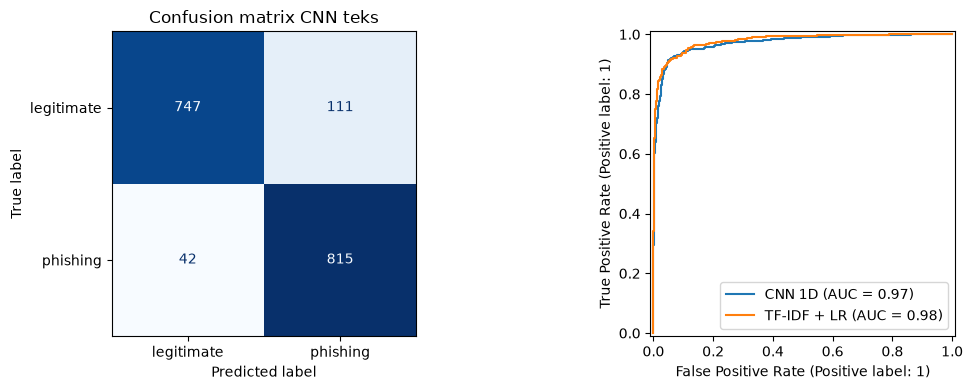

In [8]:
def evaluate_binary(y_true, probability, name):
    prediction = (np.asarray(probability).ravel() >= 0.5).astype(int)
    return {'model': name, 'accuracy': accuracy_score(y_true, prediction),
            'precision': precision_score(y_true, prediction, zero_division=0),
            'recall': recall_score(y_true, prediction, zero_division=0),
            'F1': f1_score(y_true, prediction, zero_division=0),
            'ROC-AUC': roc_auc_score(y_true, probability),
            'average precision': average_precision_score(y_true, probability)}
test_loss, test_acc = text_cnn.evaluate(X_test, y_test, verbose=0)
cnn_probability = text_cnn.predict(X_test, verbose=0).ravel()
baseline_probability = baseline.predict_proba(test_df.url)[:, list(baseline.classes_).index(1)]
text_results = pd.DataFrame([
    dict(evaluate_binary(y_test, cnn_probability, 'CNN 1D karakter'), waktu_fit_detik=cnn_seconds),
    dict(evaluate_binary(y_test, baseline_probability, 'TF-IDF + Logistic Regression'), waktu_fit_detik=baseline_seconds)
])
display(text_results)
print('Loss uji CNN:', test_loss)
print(classification_report(y_test, (cnn_probability >= 0.5).astype(int),
                            target_names=['legitimate', 'phishing'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, cnn_probability >= 0.5,
    display_labels=['legitimate', 'phishing'], ax=axes[0], cmap='Blues', colorbar=False)
RocCurveDisplay.from_predictions(y_test, cnn_probability, ax=axes[1], name='CNN 1D')
RocCurveDisplay.from_predictions(y_test, baseline_probability, ax=axes[1], name='TF-IDF + LR')
axes[0].set_title('Confusion matrix CNN teks')
plt.tight_layout()
plt.show()

## Langkah 9 — Contoh prediksi dan analisis kesalahan
Tampilkan contoh dari data uji dan beberapa prediksi yang salah. Prediksi ini berasal dari URL uji yang tidak dipakai dalam fitting. Nilai probabilitas model bukan jaminan keamanan sebuah situs.

In [9]:
predictions = test_df[['url', 'status']].reset_index(drop=True).copy()
predictions['probabilitas phishing'] = cnn_probability
predictions['prediksi'] = np.where(cnn_probability >= 0.5, 'phishing', 'legitimate')
predictions['benar'] = predictions['status'] == predictions['prediksi']
with pd.option_context('display.max_colwidth', 95):
    display(predictions.head(10))
    print('Contoh kesalahan:')
    display(predictions.loc[~predictions.benar].head(10))

,url,status,probabilitas phishing,prediksi,benar
0,https://www.downloadsarab.com/,legitimate,0.043356,legitimate,True
1,https://drive.google.com/file/d/1Ek__rSuML6v9EyfKBUz-0rl81Omz1BN-/view?usp=sharing?88674169...,phishing,0.989064,phishing,True
2,https://superuser.com/questions/479671/all-subdomains-are-redirecting-to-main-domain,legitimate,0.101626,legitimate,True
3,http://www.nchsoftware.com/classic/index.html,legitimate,0.435110,legitimate,True
4,https://bodylounge-bna.de/sites/default/files/tradekeyhtml.html/,phishing,0.528075,phishing,True
5,https://paypal-support-help-inc.blogspot.com/?m=0,phishing,0.987929,phishing,True
6,http://newsletter9707fb85e61e055593f03a43ab.dns-cloud.net/jhhh/indexa.php,phishing,0.996029,phishing,True
7,http://www.totallandscapecare.com/landscaping/virtual-reality-landscaping/,legitimate,0.008391,legitimate,True
8,http://www.frete-facil.com/,legitimate,0.151092,legitimate,True
9,http://internetserviceprovidersnyc.weebly.com/,legitimate,0.432017,legitimate,True


Contoh kesalahan:


,url,status,probabilitas phishing,prediksi,benar
15,http://www.neutralsources.com/-/re.html,phishing,0.333320,legitimate,False
19,http://publishing.cdlib.org/ucpressebooks/view?docId=ft009nb0cv;brand=escho,legitimate,0.964243,phishing,False
24,http://ufcfullvideofight.blogspot.com,legitimate,0.879628,phishing,False
28,http://www.diystompboxes.com/smfforum/index.php?topic=38449.0,legitimate,0.969853,phishing,False
31,http://www.kamicemc.com/images/docs/astkatalog.pdf,legitimate,0.541063,phishing,False
46,http://pbarcelli.blogspot.com/,legitimate,0.923908,phishing,False
53,http://www.marinasirtis.tv/libraries/mint/1/wex.asp.htm,phishing,0.264067,legitimate,False
63,http://cleverhands.com/,phishing,0.256543,legitimate,False
99,https://www.skecherstanio.pl/,phishing,0.013863,legitimate,False
114,http://beachfield.co.uk,legitimate,0.691915,phishing,False


## Langkah 10 — Kesimpulan dan kaitan dengan CNN gambar

| Komponen | CNN gambar | CNN teks URL |
|---|---|---|
| Input | Piksel RGB 64×64×3 | Maksimal 256 ID karakter |
| Representasi | Piksel dinormalisasi | Embedding yang dipelajari |
| Konvolusi | Conv2D pada tinggi dan lebar | Conv1D sepanjang urutan |
| Pola lokal | Tepi, tekstur, bagian objek | Rangkaian karakter URL |
| Pooling | MaxPool2D lalu Flatten | GlobalMaxPooling1D |
| Target | cats / dogs | legitimate / phishing |

CNN dapat diterapkan pada teks karena konvolusi juga dapat mempelajari pola lokal dalam urutan. Pada URL, tokenisasi karakter mempertahankan simbol seperti `/`, `.`, dan `-`. Pembanding TF-IDF dapat mengungguli CNN pada dataset kecil; nilai aktual di bawah menentukan hasil run ini. Dataset URL ini tidak mewakili semua tugas NLP. Untuk menilai generalisasi lebih lanjut diperlukan pemisahan berdasarkan domain/waktu, pengulangan seed, dan dataset eksternal. Akurasi gambar dan teks berasal dari tugas berbeda sehingga tidak dibandingkan sebagai kompetisi langsung.

In [10]:
cnn_row, baseline_row = text_results.iloc[0], text_results.iloc[1]
print(f"CNN teks: akurasi {cnn_row['accuracy']:.2%}, F1 {cnn_row['F1']:.4f}, ROC-AUC {cnn_row['ROC-AUC']:.4f}.")
print(f"TF-IDF + LR: akurasi {baseline_row['accuracy']:.2%}, F1 {baseline_row['F1']:.4f}.")
print(f"Selisih akurasi CNN terhadap pembanding: {(cnn_row['accuracy']-baseline_row['accuracy'])*100:+.2f} poin persentase.")
print(f'CNN berlatih selama {cnn_seconds:.2f} detik, dengan {len(history.history["loss"])} epoch.')
print('CNN berhasil memproses dataset teks menggunakan konvolusi 1D pada embedding karakter.')

CNN teks: akurasi 91.08%, F1 0.9142, ROC-AUC 0.9725.
TF-IDF + LR: akurasi 91.90%, F1 0.9199.
Selisih akurasi CNN terhadap pembanding: -0.82 poin persentase.
CNN berlatih selama 123.25 detik, dengan 10 epoch.
CNN berhasil memproses dataset teks menggunakan konvolusi 1D pada embedding karakter.


### Pembahasan hasil run tersimpan

CNN 1D selesai setelah **10 epoch** karena early stopping, dan bobot **epoch 7** dipulihkan berdasarkan loss validasi terendah. Pada **1.715 URL uji**, model mencapai akurasi **91,08%**, F1 phishing **0,9142**, dan ROC-AUC **0,9725**. Recall phishing **0,9510** lebih tinggi daripada precision phishing **0,8801**: model berhasil menangkap sebagian besar phishing, tetapi masih memberikan sejumlah prediksi phishing pada URL legitimate.

Pembanding TF-IDF karakter + Logistic Regression memperoleh akurasi **91,90%** dan F1 **0,9199**. CNN lebih rendah sekitar **0,82 poin persentase** pada run ini. Dengan demikian, CNN dapat bekerja pada teks URL, tetapi belum mengungguli pembanding yang lebih sederhana pada split ini. Waktu fit CNN sekitar **123,25 detik**, sedangkan pembanding sekitar **5,46 detik**, dengan cakupan pengukuran yang telah dijelaskan pada Langkah 7.

Satu URL duplikat dibuang sebelum split. Ada **349 hostname** yang muncul pada data latih dan uji; pemisahan dilakukan berdasarkan URL, sehingga hasil belum membuktikan generalisasi ke domain yang sama sekali baru. Sekitar **1,22%** URL uji dipotong pada 256 karakter. Akurasi teks ini tidak dapat dibandingkan langsung dengan akurasi Cat vs Dog karena dataset, target, dan protokolnya berbeda.